# Partitioning uncertainty by year instead of GWL

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import copy
import zarr
import warnings
from tqdm.notebook import tqdm
from dask.diagnostics import ProgressBar
from matplotlib import colors as mcolors

import distributed

from funcs_support import get_filepaths,get_params,utility_save
from funcs_readregs import coeffs_mortality, coeffs_gdppc
from funcs_processing import calc_uncerts
from funcs_plot import plot_map, vals_to_color_triangle

dir_list = get_params()

In [2]:
from distributed import Client

# Start dask client 
client = Client()
display(client)

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /node/crhtc14.hpc.ucar.edu/64094/proxy/8787/status,
Dashboard: /node/crhtc14.hpc.ucar.edu/64094/proxy/8787/status,Workers: 6
Total threads: 18,Total memory: 144.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:46031,Workers: 0
Dashboard: /node/crhtc14.hpc.ucar.edu/64094/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:39965,Total threads: 3
Dashboard: /node/crhtc14.hpc.ucar.edu/64094/proxy/40883/status,Memory: 24.00 GiB
Nanny: tcp://127.0.0.1:36615,


2026-10-19 19:48:48,718 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle a52f30105199202cc4b1c3c5149cc749 initialized by task ('rechunk-merge-rechunk-transfer-1d1f655bdbbda7276cdb4f488ae69427', 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2) executed on worker tcp://127.0.0.1:38929
2026-10-19 19:48:49,653 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle a52f30105199202cc4b1c3c5149cc749 deactivated due to stimulus 'task-finished-1792460929.6529264'


In [3]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':True},
               'gdppc':{'varname':'tasmeanpoly','geo_typ':'adm1','popwght':True},
              'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','popwght':True}}

#params_proc = {'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','popwght':True}}


In [4]:
overwrite = True
ssp = 'ssp245'
for proc in ['payroll']:#params_proc:
    output_fn = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}_byyr.zarr'
    if overwrite or (not os.path.exists(output_fn)):
        #---------------------------
        # Setup
        #---------------------------
        # Load impacts projections
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}*_agg-1deg_*ALLTIMEFRAMES*{'*popwght*'*params_proc[proc]['popwght']}.zarr'))
        def load_impact(fn):
            ds_tmp = xr.open_zarr(fn,consolidated=False)
            ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
            ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
        
            ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
            ds_tmp = ds_tmp.reset_index('idv')
            ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
            ds_tmp = ds_tmp.drop_vars(['flag_has_historical_duplicates','flag_resolution','flag_has_data','variable'],errors='ignore')
            return ds_tmp
        
        with warnings.catch_warnings():
            # Silence zarr warnings related to the /.done flags used
            warnings.filterwarnings('ignore')
            dss = xr.concat([load_impact(fn) for fn in fns],
                        dim='idv',join='outer')

        # SUBSET TO DESIRED SSP 
        dss = dss.isel(idv = (dss.experiment.load() == ssp))
        
        dss = dss.chunk({'poly_idx':50,'idv':-1,'proj_base':-1,'gwl':-1})

        # Save temporary rechunked file to make dask graphing more stable
        tmp_fn = dir_list['proc']+'tmp/uncert_rechunk_cache_tmp.zarr'
        dss = dss.reset_index('idv')
        for v in dss.coords:
            dss[v] = dss[v].load()
        utility_save(dss.drop_encoding(),tmp_fn,zarr_mode = 'w')
        dss = xr.open_zarr(tmp_fn)
        for v in ['model','exprun']:
            # Explicitly cast these dims as objects because of a numpy bug
            dss[v] = dss[v].astype(object)
        dss = dss.set_index(idv = ['model','exprun'])
        
        # Figure out how many BCD-ME members reach a given GWL
        # (copy.deepcopy() necessary as a workaround around a numpy bug
        # affecting the unstack a few lines down that's triggered 
        # indirectly by the reset_index here)
        gwl_counter = copy.deepcopy(dss.maxgwl).load().reset_index('idv').groupby(['model','maxgwl']).count()
        gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
        #print(gwl_counter)
        
        uncerts_all = []
        #---------------------------
        # Uncertainty partitioning over all runs
        #---------------------------
        dss_tmp = dss.unstack('idv')['d'+proc]
        dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1}).unify_chunks()
        
        # Calculate uncertainty partitioning
        with warnings.catch_warnings():
            # Ignoring chunk increase warnings and divide by 0s in uncertainty 
            # partitioning (happens over ocean, e.g.)
            warnings.filterwarnings('ignore')
            uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()

        uncerts['numruns'] = (~np.isnan(dss_tmp.mean('poly_idx'))).sum('exprun').load()
        uncerts = uncerts.expand_dims({'sample':['allruns']})
        
        uncerts_all.append(uncerts)


        #---------------------------
        # Uncertainty partitioning over only models with > 1 run
        #---------------------------

        nruns = 3
        gwlmods = gwl_counter.sel(maxgwl=2070)
        proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
        
        dss_tmp = dss.unstack('idv')['d'+proc]
        dss_tmp = dss_tmp.sel(model=proc_mods)
        dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1}).unify_chunks()
        
        # Calculate uncertainty partitioning
        with warnings.catch_warnings():
            # Ignoring chunk increase warnings and divide by 0s in uncertainty 
            # partitioning (happens over ocean, e.g.)
            warnings.filterwarnings('ignore')
            uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()

        uncerts['numruns'] = (~np.isnan(dss_tmp.mean('poly_idx'))).sum('exprun').load()
        uncerts = uncerts.expand_dims({'sample':[f'{str(nruns)}runs{str(dss_tmp.sizes['model'])}mods']})
        
        uncerts_all.append(uncerts)

        #---------------------------
        # Uncertainty partitioning over only models with > 1 run,
        # but allowing different models over different timeperiods
        # if they fit the run limit
        #---------------------------
        nruns = 3
        dss_tmp = dss.unstack('idv')['d'+proc]
        dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1}).unify_chunks()
        
        dss_tmp = dss_tmp.where((~np.isnan(dss_tmp)).sum('exprun')>=nruns)
        
        # Calculate uncertainty partitioning
        with warnings.catch_warnings():
            # Ignoring chunk increase warnings and divide by 0s in uncertainty 
            # partitioning (happens over ocean, e.g.)
            warnings.filterwarnings('ignore')
            uncerts = xr.map_blocks(calc_uncerts,dss_tmp).compute()

        uncerts['numruns'] = (~np.isnan(dss_tmp.mean('poly_idx'))).sum('exprun').load()
        uncerts = uncerts.expand_dims({'sample':[f'atleast{str(nruns)}runs']})
        
        uncerts_all.append(uncerts)
        
        #---------------------------
        # Export
        #---------------------------
        # Concatenate into single ds
        uncerts_all = xr.concat(uncerts_all,dim='sample')
        uncerts_all = uncerts_all.set_coords('numruns')
        uncerts_all = uncerts_all.where(uncerts_all.sum('typ')>0)
        
        # Export
        uncerts_all.attrs = {'SOURCE':'4d_partition_uncertainty_byyr.ipynb',
                             'DESCRIPTION':f'Uncertainty partitioning of projections of {proc} between model, internal, and reanalysis sources'}
        
        utility_save(uncerts_all,output_fn,zarr_mode = 'w')

        os.system('rm -rf '+tmp_fn)
        print('Temporary file '+tmp_fn+' removed.')
    else:
        print(output_fn+' exists!')
    


/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=10, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning 

/glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of freedom <= 0 for slice.
  result = getattr(npmodule, name)(values, axis=axis, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/xarray/core/nputils.py:242: RuntimeWarning: Degrees of fre

/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_payroll_byyr.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=10, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_payroll_byyr.zarr saved!
Temporary file /glade/derecho/scratch/schwarzwald/impact_uncertainty/tmp/uncert_rechunk_cache_tmp.zarr removed.


In [ ]:
## Note: TaiESM1 is the odd one out on payroll that's causing model unc to blow up with the all runs 

In [15]:
proc = 'gdppc'

imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}

uncerts = {'gwl':xr.open_zarr(dir_list['proc']+'uncert_parts/uncert_parts_gdppc.zarr'),
           'byyr':xr.open_zarr(dir_list['proc']+'uncert_parts/uncert_parts_gdppc_byyr.zarr')}
for typ in uncerts:
    uncerts[typ] = uncerts[typ].sel(imp_params[proc])

In [16]:
dunc = (uncerts['gwl'].sel(sample='allruns',typ='raw',gwl=2,drop=True).uncmod / 
 uncerts['byyr'].sel(sample='atleast3runs',typ='raw',gwl=2040,drop=True).uncmod).load()

In [5]:
import numpy as np
import matplotlib.colors as mcolors
import cmocean

n = 256
orig = cmocean.cm.amp(np.linspace(0, 1, n))

# Weiß -> Farbe bei 5 % der Original-Colormap
target = orig[int(0.05 * n)]

fade = np.column_stack([
    np.linspace(1, target[0], 16),
    np.linspace(1, target[1], 16),
    np.linspace(1, target[2], 16),
    np.ones(16)
])

colors = orig.copy()
colors[:16] = fade

amp_white = mcolors.ListedColormap(colors, name="amp_white")

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/byyr_vs_gwl_scatter.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/byyr_vs_gwl_scatter.png saved!


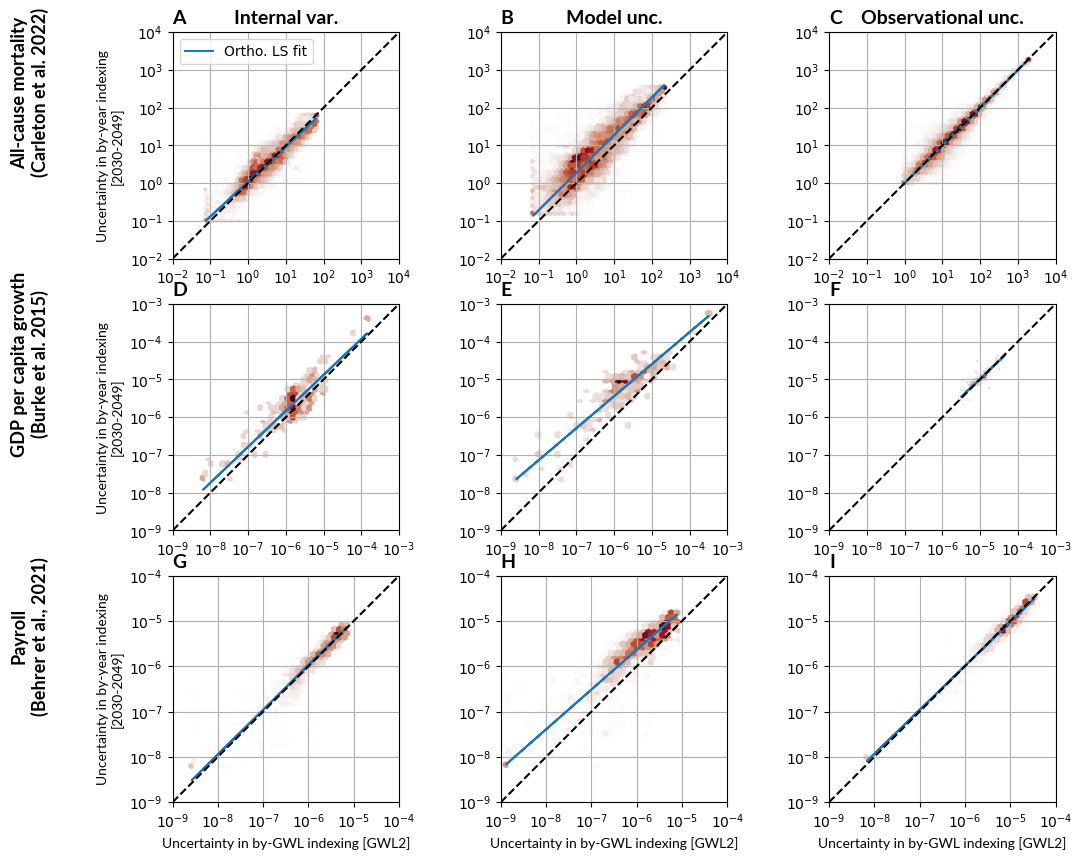

In [6]:
from matplotlib import pyplot as plt
import string
from funcs_support import utility_print
import matplotlib as mpl
from scipy import odr
extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}

subplot_lettering = string.ascii_uppercase
reg_typ = 'ortho' # ols

save_fig = True
output_fn = dir_list['figs']+'extra_figs/byyr_vs_gwl_scatter'

unc_source_names = {'uncint':'internal var.',
                                    'uncmod':'model unc.',
                                    'uncobs':'observational unc.',
                                    'uncreg':'regression unc.',
                                    'uncsce':'scenario unc.'}
proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}


imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}

fig = plt.figure(figsize=(12,10))
for row_idx,proc in enumerate(['mortality','gdppc','payroll']):
    
    uncerts = {'gwl':xr.open_zarr('/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_'+proc+'.zarr'),
               'byyr':xr.open_zarr('/glade/derecho/scratch/schwarzwald/impact_uncertainty/uncert_parts/uncert_parts_'+proc+'_byyr.zarr')}
    for typ in uncerts:
        uncerts[typ] = uncerts[typ].sel(imp_params[proc])
    
    
    droplist = ['numruns','obstreat','resolution','timeframe']
    uncs = xr.merge([uncerts['byyr'].sel(sample='atleast3runs',typ='raw',gwl=2040,drop=True).to_dataarray().to_dataset(name='byyr').drop_vars(droplist,errors='ignore'),
                    uncerts['gwl'].sel(sample='allruns',typ='raw',gwl=2,drop=True).to_dataarray().to_dataset(name='bygwl').drop_vars(droplist,errors='ignore')] ,
              compat='no_conflicts',join='outer').load()
    uncs = uncs.dropna('poly_idx',how='any')

    # Winsorize (payroll has some 0-values that mess up the log scale otherwise)
    uncs = uncs.clip(min=uncs.quantile(0.01,dim='poly_idx'),
                  max=uncs.quantile(0.99,dim='poly_idx'))
    # Get in log scale for ease of reading
    uncs = np.log10(uncs)
    
    # Get min/max for line-plotting, homogenization between plots
    min,max = np.min([uncs.byyr.min(),uncs.bygwl.min()]),np.max([uncs.byyr.max(),uncs.bygwl.max()])
    min=np.floor(min)
    max=np.ceil(max)
    
    
    for plt_idx,unc in enumerate(['uncint','uncmod','uncobs']):
        ax = plt.subplot(3,3,row_idx*3 + plt_idx+1)
    
        uncs_tmp = uncs.sel(variable=unc).set_index(poly_idx = ['bygwl']).rename({'poly_idx':'bygwl'})
        
        X = uncs_tmp.to_dataframe().reset_index()['bygwl']
        y = uncs_tmp.to_dataframe().reset_index()['byyr']
        
        # plot Hexmap
        plt.hexbin(X,
                   y,
                   cmap=amp_white,gridsize=30)

        if reg_typ == 'ols':
            # Get fit
            fit = np.polyfit(X,y,deg=1)
            # Plot fit
            plt.plot(X,X*fit[0]+fit[1],color='tab:blue',label='OLS fit')

        elif reg_typ == 'ortho':
            poly_model = odr.polynomial(1) 
            data = odr.Data(X, y) 
            odr_obj = odr.ODR(data, poly_model)
            output = odr_obj.run()
            coefficients = output.beta 
            # 6. Predict using the fitted parameters
            # Convert to a NumPy polynomial and evaluate
            p = np.poly1d(coefficients[::-1])
            y_fit = p(X)
            plt.plot(X,y_fit,color='tab:blue',label='Ortho. LS fit')
        
        # Plot guideline
        plt.plot([min,max],
                 [min,max],
                 color='k',linestyle='--')
        
        ax.set_xlim(min,max)
        ax.set_ylim(min,max)
        ticks = np.arange(min,max+1)
        ax.set_xticks(ticks,
                      [r'$10^{'+str(int(k))+r'}$' for k in ticks])
        ax.set_yticks(ticks,
                      [r'$10^{'+str(int(k))+r'}$' for k in ticks])
        ax.set_aspect('equal')
        ax.grid()
    
        # Annotate
        if row_idx == 0:
            ax.set_title(unc_source_names[unc].capitalize(),font = extra_fonts['lato-bold'],fontsize=14)
    
        if plt_idx == 0:
            ax.set_ylabel('Uncertainty in by-year indexing\n[2030-2049]',
                          font = extra_fonts['lato'])
        if row_idx == 2:
            ax.set_xlabel('Uncertainty in by-GWL indexing [GWL2]',
                         font = extra_fonts['lato'])

        # Subplot labeling
        ax.annotate(subplot_lettering[row_idx*3+plt_idx]+'',(0,1.025),xycoords = 'axes fraction',
                                        va = 'bottom',font=extra_fonts['lato-bold'],fontsize=14)

        if row_idx == 0 and plt_idx == 0:
            ax.legend()

        if plt_idx == 0:
            axpos = ax.get_position()
            ann_coords = (0.025,
                          axpos.y0+axpos.height/2)
            
            ann = ax.annotate(proc_full_names[proc],
                        ann_coords,
                        xycoords = 'figure fraction',
                        rotation=90,
                        ha='center',va='center',
                       font=extra_fonts['lato-bold'],
                       fontsize=13)

if save_fig:
    utility_print(output_fn)
